# EDA Report

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Illustrative retail customer records: keep original values for inspection.
df = pd.DataFrame({
    "Customer_ID": [101,102,103,104,105,106,107,108,109,110,110,111,112,113,114,115],
    "Age": [22,28,35,42,31,27,45,39,23,52,52,np.nan,29,-5,37,41],
    "Monthly_Income": [25000,32000,48000,65000,41000,30000,75000,58000,28000,92000,92000,38000,36000,44000,51000,250000],
    "Monthly_Spend": [8000,11000,17000,24000,14500,9000,28000,20500,8500,32000,32000,12000,np.nan,15000,19000,61000],
    "Orders": [2,3,5,7,4,2,8,6,2,9,9,3,4,5,-1,12],
    "Department": ["Electronics","Fashion","Grocery","Electronics","Fashion","Grocery","Electronics","Fashion","Grocery","Electronics","Electronics","Fashion","Grocery","Unknown","Fashion","Electronics"],
    "Membership": ["Basic","Basic","Silver","Gold","Silver","Basic","Gold","Silver","Basic","Gold","Gold","Basic","Silver","Basic","Gold","Gold"],
    "Purchased": ["No","No","Yes","Yes","Yes","No","Yes","Yes","No","Yes","Yes","No","Yes","No","Yes","Yes"],
    "Signup_Date": ["2026-01-03","2026-01-07","2026-01-10","2026-01-15","2026-02-02","2026-02-08","2026-02-13","2026-02-20","2026-03-04","2026-03-09","2026-03-09","bad-date","2026-03-15","2026-03-18","2026-03-22","2026-04-01"]
})
print(df.head())

   Customer_ID   Age  Monthly_Income  Monthly_Spend  Orders   Department  \
0          101  22.0           25000         8000.0       2  Electronics   
1          102  28.0           32000        11000.0       3      Fashion   
2          103  35.0           48000        17000.0       5      Grocery   
3          104  42.0           65000        24000.0       7  Electronics   
4          105  31.0           41000        14500.0       4      Fashion   

  Membership Purchased Signup_Date  
0      Basic        No  2026-01-03  
1      Basic        No  2026-01-07  
2     Silver       Yes  2026-01-10  
3       Gold       Yes  2026-01-15  
4     Silver       Yes  2026-02-02  


# 1. Dataset Overview
# Definition
A dataset overview explains the origin, size, business context, feature names and target variable. It helps readers understand what one row represents and what the model would predict. A clear overview prevents confusion between input features, identifiers and target values.

# Business Example
A retail company stores customer income, spending, orders and membership status. Managers may use this information to understand customer behavior. The dataset also records whether a customer purchased a product. The report starts by documenting these fields before drawing conclusions.

# AI/ML Use
Features such as income and orders may help predict a purchase outcome. Purchased is the possible classification target, while Customer_ID is an identifier rather than a meaningful predictor. Dataset dimensions and data types guide feature selection. The current sample is too small to support a reliable real-world model.

# Python Example

In [2]:
print("Source: Python-created illustrative sample (not external real-world data)")
print("Domain: Retail / customer purchasing")
print("Rows:", df.shape[0], "Columns:", df.shape[1])
print("Columns:", df.columns.tolist())
print("Target: Purchased (classification)")
print("Numerical features: Age, Monthly_Income, Monthly_Spend, Orders")
print("Categorical features: Department, Membership")
print("Identifier: Customer_ID; Date-like text: Signup_Date")

Source: Python-created illustrative sample (not external real-world data)
Domain: Retail / customer purchasing
Rows: 16 Columns: 9
Columns: ['Customer_ID', 'Age', 'Monthly_Income', 'Monthly_Spend', 'Orders', 'Department', 'Membership', 'Purchased', 'Signup_Date']
Target: Purchased (classification)
Numerical features: Age, Monthly_Income, Monthly_Spend, Orders
Categorical features: Department, Membership
Identifier: Customer_ID; Date-like text: Signup_Date


# Explanation
The output records the dataset source and its dimensions. Each row represents one illustrative customer record, although duplicates may be present. The target is Purchased, and the input features describe customers and their behavior. This report preserves the raw data to identify issues rather than fixing them.

# 2. Data Quality
# Definition
Data quality analysis checks whether values are complete, consistent, correctly typed and plausible. Missing values can make some calculations incomplete. Duplicate records may overrepresent customers. Invalid entries and incorrect types can distort analysis or cause model errors.

# Business Example
A retailer may accidentally record the same purchase twice or enter a negative age. Some customers may not disclose spending. A signup date may be typed incorrectly. These issues must be documented before anyone uses the data for business decisions.

# AI/ML Use
Missing features may require imputation later, and duplicates may bias a model. Negative ages or orders are not meaningful customer measurements. Date strings must be validated before date-based feature engineering. Detecting problems now helps plan the next preprocessing sprint.

# Python Example

In [3]:
print("Missing values by column:\n", df.isna().sum())
print("Completely duplicated rows:", df.duplicated().sum())
print("Repeated customer IDs:", df.duplicated(subset=["Customer_ID"]).sum())
print("Negative ages:", (df["Age"] < 0).sum())
print("Negative order counts:", (df["Orders"] < 0).sum())
print("Unexpected departments:", (~df["Department"].isin(["Electronics","Fashion","Grocery"])).sum())
print("Invalid signup dates:", pd.to_datetime(df["Signup_Date"], errors="coerce").isna().sum())
print("Stored data types:\n", df.dtypes)

Missing values by column:
 Customer_ID       0
Age               1
Monthly_Income    0
Monthly_Spend     1
Orders            0
Department        0
Membership        0
Purchased         0
Signup_Date       0
dtype: int64
Completely duplicated rows: 1
Repeated customer IDs: 1
Negative ages: 1
Negative order counts: 1
Unexpected departments: 1
Invalid signup dates: 1
Stored data types:
 Customer_ID         int64
Age               float64
Monthly_Income      int64
Monthly_Spend     float64
Orders              int64
Department            str
Membership            str
Purchased             str
Signup_Date           str
dtype: object


# 3. Statistical Findings
# Definition
Statistical findings summarize typical values, variation, distribution shape and unusual observations. Mean and median describe the center. Standard deviation and variance describe spread. Skewness and outlier checks help identify unusual numerical patterns.

# Business Example
A retailer can compare typical income and spending across customers. A very high income may raise the mean above the median. High variability means customers behave differently. These observations may guide customer segmentation and forecasting.

# AI/ML Use
Skewed features may benefit from transformations in a future sprint. Outliers can influence some models and scaling methods. Summary statistics also help choose sensible validation rules. Any treatment should be based on business meaning, not automatic deletion.

# Python Example

In [4]:
numeric = ["Age", "Monthly_Income", "Monthly_Spend", "Orders"]
summary = df[numeric].agg(["mean","median","var","std","min","max","skew"]).round(2)
print(summary)
for col in numeric:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25,0.75])
    iqr = q3 - q1
    flags = df[(df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)]
    print(f"{col}: IQR-flagged rows = {len(flags)}")

           Age  Monthly_Income  Monthly_Spend  Orders
mean     33.20    6.281250e+04   2.076667e+04    5.00
median   35.00    4.600000e+04   1.700000e+04    4.50
var     200.89    2.940696e+09   1.891381e+08   11.20
std      14.17    5.422818e+04   1.375275e+04    3.35
min      -5.00    2.500000e+04   8.000000e+03   -1.00
max      52.00    2.500000e+05   6.100000e+04   12.00
skew     -1.23    3.050000e+00   1.920000e+00    0.39
Age: IQR-flagged rows = 1
Monthly_Income: IQR-flagged rows = 1
Monthly_Spend: IQR-flagged rows = 1
Orders: IQR-flagged rows = 0


# Explanation
The table gives center, spread and skewness for each numerical feature. Compare mean with median to notice asymmetry. IQR flags are candidates for investigation, not proof of incorrect data. The negative age and order values are clearly invalid; the highest income may be a genuine high-value customer and needs verification.

# 4. Relationship Findings
# Definition
Relationship analysis examines whether two or more features move together or differ by group. Correlation summarizes linear association between numerical columns. Grouped statistics compare typical values across categories. Relationships can suggest useful predictors but do not prove causation.

# Business Example
Customers with higher incomes may spend more each month. Gold members may also place more orders. A retailer can investigate these patterns to understand customer segments. Small datasets, however, can produce unstable patterns.

# AI/ML Use
Highly correlated inputs can suggest redundancy or potential multicollinearity in some models. Group differences can reveal predictive signals. Relationships involving the target can guide later feature selection. Findings should be checked with larger representative data before modeling.

# Python Example

In [5]:
print("Numerical correlations:\n", df[numeric].corr().round(2))
print("Mean spending by membership:\n", df.groupby("Membership")["Monthly_Spend"].mean().round(2))
print("Purchase counts by membership:\n", pd.crosstab(df["Membership"], df["Purchased"]))

Numerical correlations:
                  Age  Monthly_Income  Monthly_Spend  Orders
Age             1.00            0.42           0.54    0.50
Monthly_Income  0.42            1.00           0.97    0.78
Monthly_Spend   0.54            0.97           1.00    0.85
Orders          0.50            0.78           0.85    1.00
Mean spending by membership:
 Membership
Basic     10583.33
Gold      32666.67
Silver    17333.33
Name: Monthly_Spend, dtype: float64
Purchase counts by membership:
 Purchased   No  Yes
Membership         
Basic        6    0
Gold         0    6
Silver       0    4


# Explanation
The correlation matrix shows direction and strength of linear relationships. Group means summarize spending by membership but may be influenced by outliers. The cross-tab shows how purchase labels are distributed within each membership category. None of these patterns alone establishes a causal relationship.

# 5. Visualization Findings
# Definition
Visualizations turn tables into patterns that are easier to compare. Histograms reveal numerical distributions. Box plots highlight spread and unusual values. Bar charts compare category frequencies, while heatmaps summarize numerical correlations.

# Business Example
A sales manager may need to see whether most customers spend modest amounts while a few spend much more. A histogram communicates that shape. A category chart can show which departments occur most often. These visual checks support clearer business reporting.

# AI/ML Use
Charts can expose skewness, outliers, imbalanced categories and related features. They also help check whether summary statistics hide unusual distributions. Visual observations should be supported by the underlying data. The goal is to document findings rather than automatically change features.

# Python Example

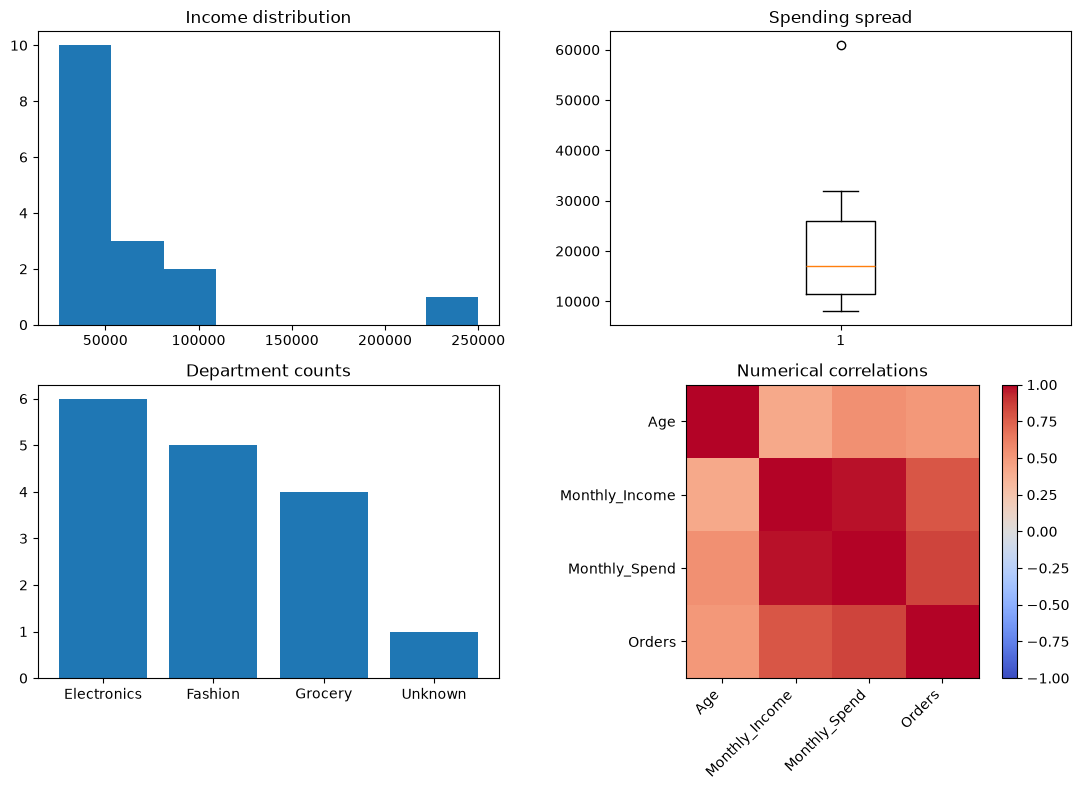

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0,0].hist(df["Monthly_Income"].dropna(), bins=8)
axes[0,0].set_title("Income distribution")
axes[0,1].boxplot(df["Monthly_Spend"].dropna())
axes[0,1].set_title("Spending spread")
counts = df["Department"].value_counts()
axes[1,0].bar(counts.index, counts.values)
axes[1,0].set_title("Department counts")
cor = df[numeric].corr()
im = axes[1,1].imshow(cor, vmin=-1, vmax=1, cmap="coolwarm")
axes[1,1].set_xticks(range(len(numeric)), numeric, rotation=45, ha="right")
axes[1,1].set_yticks(range(len(numeric)), numeric)
axes[1,1].set_title("Numerical correlations")
fig.colorbar(im, ax=axes[1,1])
plt.tight_layout()
plt.show()

# Explanation
The income histogram allows inspection of the long upper tail caused by a high-income observation. The spending box plot shows possible extreme spending values. Department counts reveal the relative representation of categories, including the unexpected Unknown entry. The heatmap makes correlation directions visible, but the small sample limits generalization.

# 6. Potential Data Problems
# Definition
Potential data problems are issues discovered during EDA that could affect analysis or model training. The purpose is to document their locations and likely impact. A flagged observation is not always wrong. Decisions about fixing or retaining values should be made during preprocessing.

# Business Example
An invalid negative order count could distort demand analysis. A repeated customer record could inflate purchase totals. An unusually large income may be legitimate rather than a mistake. Managers should confirm the meaning of these values before changing them.

# AI/ML Use
Missing spending or age values may block certain estimators. Duplicates can leak repeated observations across train and test sets. Unexpected categories may need consistent encoding rules. Invalid dates must be addressed before creating time-based features.

# Python Example

In [7]:
issues = pd.DataFrame({
    "Issue": ["Missing values", "Duplicate full rows", "Repeated IDs", "Invalid negative ages", "Invalid negative orders", "Unexpected department", "Invalid dates", "Date stored as text"],
    "Count_or_status": [int(df.isna().sum().sum()), int(df.duplicated().sum()), int(df.duplicated("Customer_ID").sum()), int((df.Age < 0).sum()), int((df.Orders < 0).sum()), int((~df.Department.isin(["Electronics","Fashion","Grocery"])).sum()), int(pd.to_datetime(df.Signup_Date, errors="coerce").isna().sum()), str(df.Signup_Date.dtype)]
})
print(issues.to_string(index=False))

                  Issue Count_or_status
         Missing values               2
    Duplicate full rows               1
           Repeated IDs               1
  Invalid negative ages               1
Invalid negative orders               1
  Unexpected department               1
          Invalid dates               1
    Date stored as text             str


# Explanation
This issue register consolidates problems already identified by EDA. It does not alter the underlying dataset. Each issue should be verified against business rules or source records. Recording the counts now makes it easier to evaluate the effects of later preprocessing.

# 7. Recommendations for the Next Preprocessing Sprint
# Definition
Recommendations translate EDA findings into possible future data-cleaning and feature-preparation steps. They are proposals, not completed transformations. Each proposal should explain the problem it addresses. Decisions must be validated after inspecting the source and model requirements.

# Business Example
The retail team could check invalid customer ages against original records. They could investigate repeated customer IDs before removing duplicates. High-income observations should be verified rather than discarded automatically. Consistent membership and department labels can improve reporting.

# AI/ML Use
Possible next steps include missing-value treatment, encoding categories and correcting date types. Scaling may help algorithms sensitive to feature magnitude. Skewed features may benefit from transformations, while dates could support feature engineering. Any fitted preprocessing must use training data only to prevent leakage.

# Python Example

In [8]:
recommendations = pd.DataFrame({
    "Observed issue": ["Missing Age/Spend", "Repeated records/IDs", "Negative Age/Orders", "Unknown department", "Invalid/text dates", "Large income/spending values", "Categorical features", "Different numeric scales"],
    "Potential next step (NOT executed)": ["Evaluate imputation", "Verify IDs and duplicates", "Check source and correct invalid entries", "Standardize or validate categories", "Parse dates and investigate invalid strings", "Verify outliers; consider transformation if justified", "Evaluate encoding", "Consider scaling for appropriate models"]
})
print(recommendations.to_string(index=False))

              Observed issue                    Potential next step (NOT executed)
           Missing Age/Spend                                   Evaluate imputation
        Repeated records/IDs                             Verify IDs and duplicates
         Negative Age/Orders              Check source and correct invalid entries
          Unknown department                    Standardize or validate categories
          Invalid/text dates           Parse dates and investigate invalid strings
Large income/spending values Verify outliers; consider transformation if justified
        Categorical features                                     Evaluate encoding
    Different numeric scales               Consider scaling for appropriate models


# Explanation
The recommendations list possible actions without implementing them. Missing values, duplicates and invalid records should be investigated first. Encoding, scaling and feature engineering should be planned based on the chosen model. The current notebook remains an EDA report, not a preprocessing pipeline.